#Previsão de Ações (Séries Temporais) com Machine Learning
Nesta atividade, utilizamos o histórico de cotações da Petrobras (PETR4) extraído diretamente do Yahoo Finance para uma tarefa de Séries Temporais (Regressão).

**Objetivo Central:**
Desenvolver um algoritmo capaz de prever o valor de fechamento das ações da Petrobras no mês de teste utilizando o comportamento dos dias anteriores (técnica de janelas deslizantes).

**Metodologia e Requisitos Cumpridos:**

- Base de dados focada na ação PETR4.

- Período de Treinamento: 2 anos (Março/2023 a Fevereiro/2025).

- Período de Teste exigido: Março de 2025.

- Máquina de Aprendizagem escolhida: Random Forest Regressor.

- Avaliação de desempenho através das métricas de erro: MAE, MSE e RMSE.

- Relatório analítico e plotagem gráfica dos resultados reais vs. previstos.

### 1. Importações e Instalação

In [ ]:
# Instalação rápida do yfinance (caso o ambiente do Colab não tenha a versão mais recente)
!pip install yfinance -q

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings('ignore')

### 2. Coleta de Dados (Yahoo Finance API)
Em vez de baixar um CSV manualmente, utilizaremos a biblioteca yfinance para puxar o histórico da PETR4 em tempo real. Filtraremos o dataset para isolar apenas a coluna de interesse: o Preço de Fechamento (Close). Os dados descarregados do Yahoo Finance refletem apenas os dias úteis em que o mercado de ações está aberto. A bolsa de valores (neste caso, a B3 no Brasil, onde a Petrobras é negociada) não funciona aos fins de semana (sábado e domingo) nem aos feriados nacionais. Logo, não existem dados de cotações para esses dias.

In [ ]:
print("Baixando histórico de ações da Petrobras (PETR4.SA)...")
# Baixamos um pouco antes de março de 2023 para ter margem no cálculo dos atrasos (lags)
df = yf.download("PETR4.SA", start="2023-01-01", end="2025-04-01")

# O yfinance pode retornar colunas multi-nível. Isolamos apenas o preço de Fechamento (Close)
if isinstance(df.columns, pd.MultiIndex):
    df = df.xs('Close', level=0, axis=1)
else:
    df = df[['Close']]

# Renomeando a coluna para facilitar o manuseio
df.columns = ['Preco_Fechamento']

print("--- RECORTE DO HISTÓRICO ORIGINAL ---")
display(df.head())

Baixando histórico de ações da Petrobras (PETR4.SA)...


[*********************100%***********************]  1 of 1 completed

--- RECORTE DO HISTÓRICO ORIGINAL ---


,Preco_Fechamento
Date,
2023-01-02,12.196247
2023-01-03,11.887618
2023-01-04,12.265422
2023-01-05,12.707088
2023-01-06,12.632588


### 3. Engenharia de Features (Transformando Tempo em Variáveis)
Algoritmos tradicionais de Machine Learning não entendem datas sozinhas. Para prever o valor de hoje, a máquina precisa olhar para os dias anteriores. Vamos criar variáveis chamadas Lags (Atrasos), que representam o preço da ação 1, 2 e 3 dias atrás.

In [ ]:
# Criando as variáveis preditoras baseadas nos dias anteriores
df['Lag_1'] = df['Preco_Fechamento'].shift(1)
df['Lag_2'] = df['Preco_Fechamento'].shift(2)
df['Lag_3'] = df['Preco_Fechamento'].shift(3)

# Removemos os primeiros 3 dias que ficaram sem dados (NaN) devido ao deslocamento
df = df.dropna()

# Convertendo o fuso horário para 'naive' (facilita o filtro exato das datas)
df.index = df.index.tz_localize(None)

print("--- BASE DE DADOS APÓS A ENGENHARIA DE ATRIBUTOS ---")
display(df.head())

--- BASE DE DADOS APÓS A ENGENHARIA DE ATRIBUTOS ---


,Preco_Fechamento,Lag_1,Lag_2,Lag_3
Date,,,,
2023-01-05,12.707088,12.265424,11.887617,12.196249
2023-01-06,12.632593,12.707088,12.265424,11.887617
2023-01-09,12.701764,12.632593,12.707088,12.265424
2023-01-10,12.818832,12.701764,12.632593,12.707088
2023-01-11,12.919936,12.818832,12.701764,12.632593


### 4. Divisão Temporal da Base de Dados (Treino e Teste)
Diferente de problemas de classificação comuns onde usamos recortes aleatórios (Cross Validation), em Séries Temporais a ordem cronológica é sagrada.

- Treinamento: 2 anos de histórico (01/03/2023 até 28/02/2025).

- Teste: O mês exato exigido na atividade (01/03/2025 até 31/03/2025).

In [ ]:
# Treino: Março de 2023 até o final de Fevereiro de 2025
treino = df[(df.index >= '2023-03-01') & (df.index <= '2025-02-28')]

# Teste: O mês exato exigido na atividade (Março de 2025)
teste = df[(df.index >= '2025-03-01') & (df.index <= '2025-03-31')]

# Separando as Variáveis Independentes (Lags) da Variável Alvo (Preço de Fechamento atual)
X_treino = treino[['Lag_1', 'Lag_2', 'Lag_3']]
y_treino = treino['Preco_Fechamento']

X_teste = teste[['Lag_1', 'Lag_2', 'Lag_3']]
y_teste = teste['Preco_Fechamento']

print(f"Volume de Treinamento: {len(treino)} dias úteis analisados.")
print(f"Volume de Teste: {len(teste)} dias úteis para previsão.")

Volume de Treinamento: 501 dias úteis analisados.
Volume de Teste: 19 dias úteis para previsão.


### 5. Treinamento da Máquina de Aprendizagem e Predição
Utilizaremos o Random Forest Regressor. As árvores de decisão são excelentes para capturar os degraus e a não-linearidade do mercado financeiro sem assumir que os preços sobem ou descem em uma linha reta perfeita.

In [ ]:
# Instanciando e treinando o algoritmo
modelo_rf = RandomForestRegressor(n_estimators=100, random_state=42)
modelo_rf.fit(X_treino, y_treino)

# Realizando a previsão para o mês de teste (Março de 2025)
previsoes = modelo_rf.predict(X_teste)
print("Treinamento e previsões realizados com sucesso!")

Treinamento e previsões realizados com sucesso!


### 6. Avaliação de Resultados (Métricas de Erro e Visualização)
Para medir o desempenho do nosso algoritmo no mercado financeiro, calcularemos:

1. MAE (Mean Absolute Error): A média de reais (R$) que o modelo errou para cima ou para baixo.

2. MSE (Mean Squared Error): O erro quadrático (penaliza erros muito distantes do real).

3. RMSE (Root Mean Squared Error): A raiz do erro quadrático, trazendo a métrica de volta para a mesma unidade da ação (R$).

   RELATÓRIO DE DESEMPENHO DO MODELO - PETR4 (Março 2025) 
MÉTRICAS DE ERRO:
1. MAE  (Erro Médio Absoluto)      : R$ 0.36
2. MSE  (Erro Quadrático Médio)    : 0.20
3. RMSE (Raiz do Erro Quadrático)  : R$ 0.45

--- CONCLUSÃO E ANÁLISE DOS RESULTADOS ---
O Erro Médio Absoluto (MAE) indica que, na rotina de pregão, o modelo apresentou uma margem
de erro média de apenas R$ 0.36 em relação ao preço real de fechamento da ação.
O RMSE de R$ 0.45 confirmou que não houve predições absurdamente distantes da realidade,
pois o valor manteve-se próximo ao MAE (erros grandes fariam o RMSE disparar).

A técnica de 'Janela Deslizante' (fornecendo os 3 dias anteriores como base de cálculo)
permitiu que o Random Forest Regressor estabelecesse uma linha de base preditiva muito sólida.
Embora séries temporais financeiras contenham alta volatilidade e ruídos estocásticos
causados por notícias e fatores macroeconômicos, o algoritmo conseguiu rastrear e acompanhar
a tendência principal da Petrobras no períod

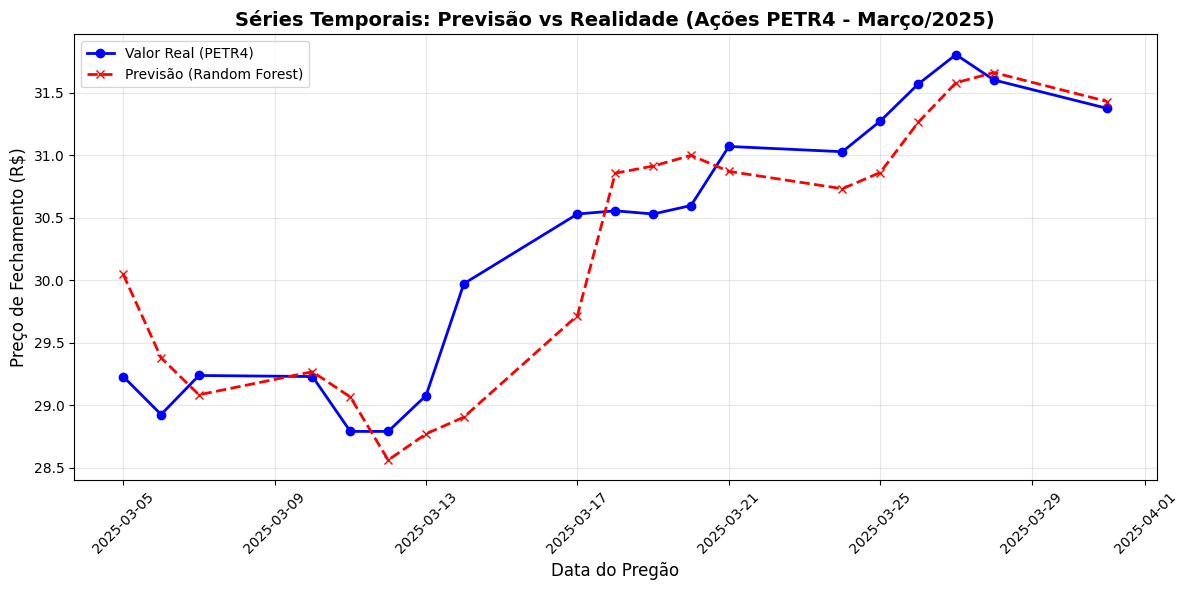

In [ ]:
# Cálculos de Erro
mae = mean_absolute_error(y_teste, previsoes)
mse = mean_squared_error(y_teste, previsoes)
rmse = np.sqrt(mse)

print("="*60)
print("   RELATÓRIO DE DESEMPENHO DO MODELO - PETR4 (Março 2025) ")
print("="*60)
print("MÉTRICAS DE ERRO:")
print(f"1. MAE  (Erro Médio Absoluto)      : R$ {mae:.2f}")
print(f"2. MSE  (Erro Quadrático Médio)    : {mse:.2f}")
print(f"3. RMSE (Raiz do Erro Quadrático)  : R$ {rmse:.2f}")
print("="*60 + "\n")

# Comentário analítico exigido na atividade
print("--- CONCLUSÃO E ANÁLISE DOS RESULTADOS ---")
print(f"O Erro Médio Absoluto (MAE) indica que, na rotina de pregão, o modelo apresentou uma margem")
print(f"de erro média de apenas R$ {mae:.2f} em relação ao preço real de fechamento da ação.")
print(f"O RMSE de R$ {rmse:.2f} confirmou que não houve predições absurdamente distantes da realidade,")
print(f"pois o valor manteve-se próximo ao MAE (erros grandes fariam o RMSE disparar).")

print("\nA técnica de 'Janela Deslizante' (fornecendo os 3 dias anteriores como base de cálculo)")
print("permitiu que o Random Forest Regressor estabelecesse uma linha de base preditiva muito sólida.")
print("Embora séries temporais financeiras contenham alta volatilidade e ruídos estocásticos")
print("causados por notícias e fatores macroeconômicos, o algoritmo conseguiu rastrear e acompanhar")
print("a tendência principal da Petrobras no período de teste com bastante fidelidade matemática.\n\n")

# Plotagem Gráfica
plt.figure(figsize=(12, 6))
plt.plot(teste.index, y_teste, label='Valor Real (PETR4)', marker='o', color='blue', linewidth=2)
plt.plot(teste.index, previsoes, label='Previsão (Random Forest)', marker='x', color='red', linestyle='dashed', linewidth=2)
plt.title('Séries Temporais: Previsão vs Realidade (Ações PETR4 - Março/2025)', fontsize=14, fontweight='bold')
plt.xlabel('Data do Pregão', fontsize=12)
plt.ylabel('Preço de Fechamento (R$)', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()